# **Activity 1** Scenario: Customer Behavior Classification (Two-Class with Decision Tree) You are analyzing customer data to predict if they will respond to a marketing campaign.


In [ ]:
import pandas as pd
from sklearn.tree import DecisionTreeClassifier
from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score
import numpy as np

In [ ]:
data={
    'Age': np.random.randint(20,60,100),
    'PurchaseFrequency': np.random.uniform(0.5,5,100).round(1),
    'RespondToCampaign': np.random.choice([0,1],100,p=(0.6,0.4)) #p is the probability of selecting 0 or 1
}

# Make response somewhat dependent on younger age and higher frequency

for i in range(100):
  if data['Age'][i]<35 and data['PurchaseFrequency'][i]>3:
    data['RespondToCampaign'][i]=1
  elif data['Age'][i]>50 and data['PurchaseFrequency'][i]<1.5:
    data['RespondToCampaign'][i]=0


In [ ]:
df=pd.DataFrame(data)
X=df[['Age','PurchaseFrequency']]
y=df['RespondToCampaign']
X_train,X_test,y_train,y_test=train_test_split(X,y,test_size=0.2,random_state=42)

In [ ]:
X_train.head()

,Age,PurchaseFrequency
55,38,2.4
88,22,2.0
26,31,0.6
42,48,4.6
69,24,0.8


In [ ]:
y_train.head()

,RespondToCampaign
55,1
88,0
26,0
42,0
69,0


In [ ]:
model=DecisionTreeClassifier(max_depth=6,random_state=42)
model.fit(X_train,y_train)
y_pred=model.predict(X_test)

In [ ]:
pd.DataFrame({'RespondToCampaign':y_pred}).head()

,RespondToCampaign
0,0
1,0
2,0
3,0
4,1


In [ ]:
accuracy_score(y_pred,y_test)

0.6

## Decision Tree checks which feature at which value will result in a split such that the resunding sub sets of the data have highest purity or level of uniformity(weighted).

# **Activity 2** Scenario: Email Spam Detection (Two-Class with Logistic Regression) You’re building a basic system to identify if an email is spam (1) or not spam (0) based on features like the number of suspicious keywords.

In [ ]:
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

In [ ]:
np.random.seed(42)
keywords=np.random.randint(0,10,100)  #no. of suspicious keywords
spam_prob=1/(1+np.exp(-(keywords-5)))
is_spam=(np.random.rand(100)<spam_prob).astype(int)

In [ ]:
is_spam

array([1, 1, 1, 0, 1, 1, 0, 1, 1, 0, 0, 1, 1, 0, 1, 0, 0, 1, 1, 0, 0, 0,
       1, 1, 1, 0, 1, 0, 1, 0, 1, 0, 0, 0, 1, 1, 1, 0, 0, 0, 1, 0, 1, 1,
       1, 0, 0, 0, 1, 1, 0, 0, 0, 0, 1, 0, 0, 1, 1, 1, 0, 0, 0, 0, 0, 1,
       0, 1, 1, 1, 1, 0, 0, 0, 1, 1, 1, 1, 0, 1, 0, 1, 1, 0, 1, 1, 0, 0,
       1, 0, 0, 0, 0, 1, 0, 1, 1, 0, 1, 1])

In [ ]:
df=pd.DataFrame({'NumSuspicionKeywords':keywords,'IsSpam':is_spam})
df.head()

,NumSuspicionKeywords,IsSpam
0,6,1
1,3,1
2,7,1
3,4,0
4,6,1


In [ ]:
X=df[['NumSuspicionKeywords']]
y=df['IsSpam']
X_train,X_test,y_train,y_test=train_test_split(X,y,test_size=0.3,random_state=42)


In [ ]:
X_train.head()

,NumSuspicionKeywords
11,7
47,3
85,7
28,6
93,9


In [ ]:
y_train.head()

,IsSpam
11,1
47,0
85,1
28,1
93,1


In [ ]:
model=LogisticRegression()
model.fit(X_train,y_train)

LogisticRegression()

In [ ]:
y_pred=model.predict(X_test)
y_pred

array([0, 0, 1, 0, 1, 0, 1, 1, 0, 1, 1, 1, 0, 0, 0, 1, 1, 1, 1, 0, 0, 1,
       1, 1, 1, 0, 1, 1, 0, 0])

In [ ]:
accuracy_score(y_pred,y_test)

0.9666666666666667

## **OPTIONAL LAB ACTIVITIES**

---




# **Activity 1** Activity 2.3: Conceptual Decision Boundary For this 1-feature problem, where would the Logistic Regression model likely place its decision boundary to classify an email as spam or not spam? (Think about a threshold value for NumSuspiciousKeywords).


# The decision boundary will be likely around 5 suspicious keywords because of the value of the exponent of e  in the sigmoid style function is keywords-5 which makes 5 suspicious keywords resulting in 0.5 probability. But it is not necessary that the decision boundary will be exactly 5 because of the randomness that has been introduced in the IsSpam column by the code which follows

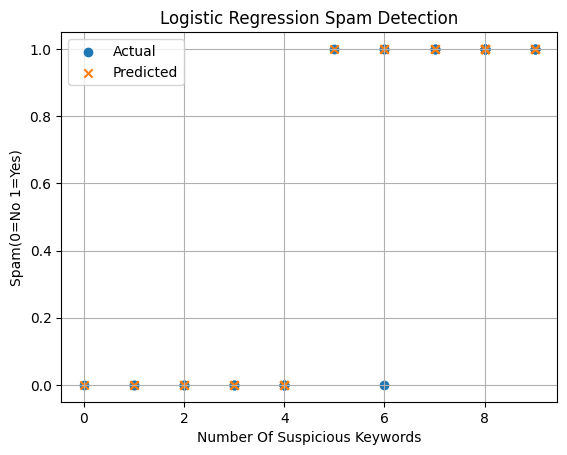

In [ ]:
plt.scatter(X_test['NumSuspicionKeywords'],y_test,label='Actual')
plt.scatter(X_test['NumSuspicionKeywords'],y_pred,marker='x',label='Predicted')
plt.xlabel('Number Of Suspicious Keywords')
plt.ylabel('Spam(0=No 1=Yes)')
plt.title('Logistic Regression Spam Detection')
plt.legend()
plt.grid()
plt.show()